# Examination of a 1D Powered Rocket Ascent w/ Drag

## 1. Governing Initial Value Problem (IVP)

To characterize aerodynamic drag losses on a sounding rocket during powered vertical flight, we model the rocket as a 1D point mass ascending through an exponential atmosphere under constant motor thrust $T$ and constant gravitational acceleration $g$. 

### State Vector & Coupled ODE System
Let $h(t)$ be the altitude, $v(t)$ be the vertical velocity, $m(t)$ be the instantaneous rocket mass, and $\Delta v_{\text{drag}}(t)$ be the cumulative velocity loss due to aerodynamic drag. Over the powered burn duration $t \in [0, t_b]$, the state vector $y(t)$ and its time derivative $\dot{y} = f(t, y)$ are governed by the non-autonomous nonlinear system:

$$y(t) = \begin{bmatrix} h(t) \\ v(t) \\ m(t) \\ \Delta v_{\text{drag}}(t) \end{bmatrix}, \qquad \frac{dy}{dt} = f(t, y) = \begin{bmatrix} v \\[6pt] \dfrac{T}{m} - g - \dfrac{\rho(h) C_D S}{2m} v|v| \\[8pt] -\dfrac{T}{I_{sp} g} \\[8pt] \dfrac{\rho(h) C_D S}{2m} v^2 \end{bmatrix}$$

### Initial Conditions & Time Domain
Assuming the rocket launches vertically from rest at sea level at $t = 0$:

$$h(0) = 0\text{ m}, \qquad v(0) = 0\text{ m/s}, \qquad m(0) = m_0, \qquad \Delta v_{\text{drag}}(0) = 0\text{ m/s}$$

The integration domain spans the powered burn phase $t \in [0, t_b]$, where burnout occurs when all propellant is expended ($m(t_b) = m_{\text{dry}}$):

$$t_b = \frac{(m_0 - m_{\text{dry}}) I_{sp} g}{T}$$

### Supporting Models
* **Exponential Atmosphere:** Air density decays exponentially with altitude $h$ according to scale height $H$:
  $$\rho(h) = \rho_0 e^{-h/H}$$
* **Cross-Sectional Reference Area:** For a cylindrical rocket body of diameter $d$:
  $$S = \frac{\pi d^2}{4}$$
* **Propellant Mass Flow Rate:** Constant mass consumption rate during motor burn:
  $$\dot{m} = -\frac{T}{I_{sp} g}$$

---

## 2. Nominal System Parameters

| Parameter | Symbol | Value | Units |
| :--- | :---: | :---: | :---: |
| Gravitational Acceleration | $g$ | $9.81$ | $\text{m/s}^2$ |
| Sea-Level Air Density | $\rho_0$ | $1.225$ | $\text{kg/m}^3$ |
| Atmospheric Scale Height | $H$ | $8500$ | $\text{m}$ |
| Liftoff (Wet) Mass | $m_0$ | $50.0$ | $\text{kg}$ |
| Burnout (Dry) Mass | $m_{\text{dry}}$ | $20.0$ | $\text{kg}$ |
| Motor Thrust | $T$ | $3000.0$ | $\text{N}$ |
| Specific Impulse | $I_{sp}$ | $230.0$ | $\text{s}$ |
| Rocket Body Diameter | $d$ | $0.15$ | $\text{m}$ |
| Reference Area | $S$ | $0.01767$ | $\text{m}^2$ |
| Drag Coefficient | $C_D$ | $0.4$ | — |
| Mass Flow Rate | $\dot{m}$ | $1.3296$ | $\text{kg/s}$ |
| Burnout Time | $t_b$ | $22.563$ | $\text{s}$ |

# The Method

The first thing to check before deciding on a method is the stiffness of the system, which is done by comparing the largest eigenvalue in the jacobian to the smallest. The stiffness is defined as $R_s = \frac{\max_i |\lambda_i|}{\min_i |\lambda_i|}$, and the IVP is stiff if $R_s >> 1$. The eigenvalues considered in the stiffness equation are from the jacobian of the IVP. For this problem, the elements of the jacobian are $J_{ij} = \frac{\partial f_i}{\partial y_j}$, and the jacobian itself comes out to be

$$
J =
\begin{pmatrix}
0 & 1 & 0 & 0 \\[6pt]
\dfrac{\rho\, C_D S\, v^2}{2mH}
& -\dfrac{\rho\, C_D S\, v}{m}
& -\dfrac{T}{m^2} + \dfrac{\rho\, C_D S\, v^2}{2m^2}
& 0 \\[8pt]
0 & 0 & 0 & 0 \\[6pt]
-\dfrac{\rho\, C_D S\, v^2}{2mH}
& \dfrac{\rho\, C_D S\, v}{m}
& -\dfrac{\rho\, C_D S\, v^2}{2m^2}
& 0
\end{pmatrix}
$$

The numerical method we chose is the RK4, justified by the proceding information.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

T = 3000.0                   # thrust (N)
G = 9.81                     # gravity (m/s^2)
CD = 0.4                     # drag coefficient
S = np.pi * 0.15**2 / 4      # reference area (m^2)
RHO0 = 1.225                 # sea-level density (kg/m^3)
H_SCALE = 8500.0             # scale height (m)
Isp = 230.0                  # specific impulse (s)
m0, m_dry = 50.0, 20.0       # liftoff and burnout mass (kg)
tb = (m0 - m_dry) * Isp * G / T      # burn time (s)

def jacobian(y):
    h, v, m, dv_drag = y
    rho = RHO0 * np.exp(-h / H_SCALE)

    J = np.zeros((4, 4))

    J[0, 1] = 1.0

    J[1, 0] = rho * CD * S * v**2 / (2 * m * H_SCALE)
    J[1, 1] = -rho * CD * S * v / m
    J[1, 2] = -T / m**2 + rho * CD * S * v**2 / (2 * m**2)
    J[3, 0] = -rho * CD * S * v**2 / (2 * m * H_SCALE)
    J[3, 1] = rho * CD * S * v / m
    J[3, 2] = -rho * CD * S * v**2 / (2 * m**2)

    return J

from IPython.display import display, HTML

display(HTML("""
<style>
.output_area {
    max-height: none !important;
}
</style>
"""))


T = 3000.0
G = 9.81
CD = 0.4
S = np.pi * 0.15**2 / 4
RHO0 = 1.225
H_SCALE = 8500.0
Isp = 230.0
m0, m_dry = 50.0, 20.0

tb = (m0 - m_dry) * Isp * G / T

def f(y):
    h, v, m, dv_drag = y
    rho = RHO0 * np.exp(-h / H_SCALE)

    return np.array([
        v,
        T / m - G - rho * CD * S / (2 * m) * v**2,
        -T / (Isp * G),
        rho * CD * S / (2 * m) * v**2
    ])

def rk4(y, dt):
    k1 = f(y)
    k2 = f(y + dt / 2 * k1)
    k3 = f(y + dt / 2 * k2)
    k4 = f(y + dt * k3)

    return y + dt / 6 * (k1 + 2*k2 + 2*k3 + k4)



def state_at(frac, dt_target=0.1):
    N = round(tb / dt_target)
    dt = tb / N

    y = np.array([0.0, 0.0, m0, 0.0])

    for _ in range(int(round(frac * N))):
        y = rk4(y, dt)

    return y

burn_fractions = [0.1, 0.25, 0.5, 0.75, 1.0]

for frac in burn_fractions:

    y = state_at(frac)
    J = jacobian(y)
    eigenvalues = np.linalg.eigvals(J)

    mags = np.abs(eigenvalues)
    nonzero = mags[mags > 1e-8]

    R_s = np.max(nonzero) / np.min(nonzero)

    print(f"Fraction of burn: {frac}")
    print("------------------------------------")
    print(f"State (h, v, m, dv_drag): {y}")
    print(f"Eigenvalues: {eigenvalues}")
    print(f"Stiffness ratio R_s: {R_s:.6f}\n")


Fraction of burn: 0.1
------------------------------------
State (h, v, m, dv_drag): [135.09822593 118.67661113  46.94690265   0.95725412]
Eigenvalues: [ 0.         -0.02709469  0.00555081  0.        ]
Stiffness ratio R_s: 4.881218

Fraction of burn: 0.25
------------------------------------
State (h, v, m, dv_drag): [814.48171463 293.66608498  42.56637168  14.65843014]
Eigenvalues: [ 0.         -0.0680576   0.01377746  0.        ]
Stiffness ratio R_s: 4.939778

Fraction of burn: 0.5
------------------------------------
State (h, v, m, dv_drag): [3312.41665541  579.28100095   35.          114.81316006]
Eigenvalues: [ 0.         -0.12378122  0.02671975  0.        ]
Stiffness ratio R_s: 4.632573

Fraction of burn: 0.75
------------------------------------
State (h, v, m, dv_drag): [7382.05767779  854.12790821   27.43362832  333.72694471]
Eigenvalues: [ 0.         -0.1508053   0.03768691  0.        ]
Stiffness ratio R_s: 4.001530

Fraction of burn: 1.0
------------------------------------

## IVP Stiffness

The jacobian depends on the current state, meaning that the eigenvalues of the jacobian could change over time. To capture the worst stiffness ratio throughout the flight duration, we split the burn interval into different burn fractions, where a fraction of burn of 0 is the time of liftoff and a burn fraction of 1 would be the time of burnout. The burn fractions we chose were 0.1, 0.25, 0.50, 0.75, and 1.00. The stiffness ratio changes slowly over the interval, peaking at $R_s = 4.940$. This means that the IVP is far from being stiff because $R_s$ is not $>> 1$. This test shows that non stiff methods such as the RK4 we chose to use.

## Accuracy

The next thing that we checked was the accuracy. This was done by checking the convergence of the RK4.

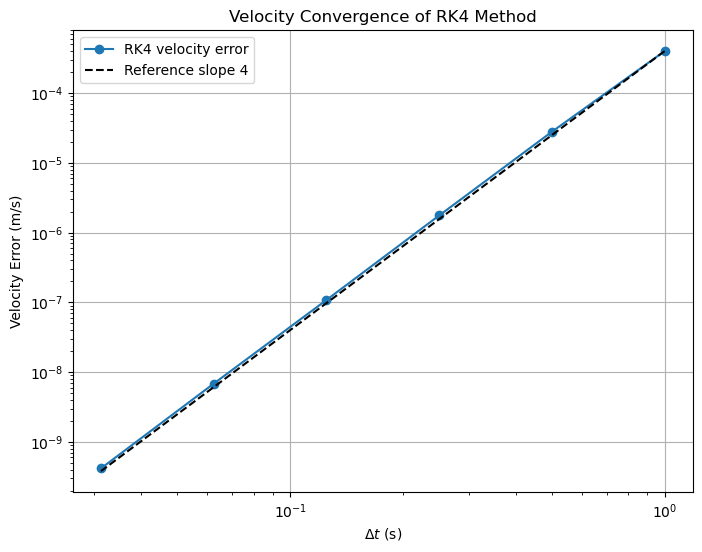

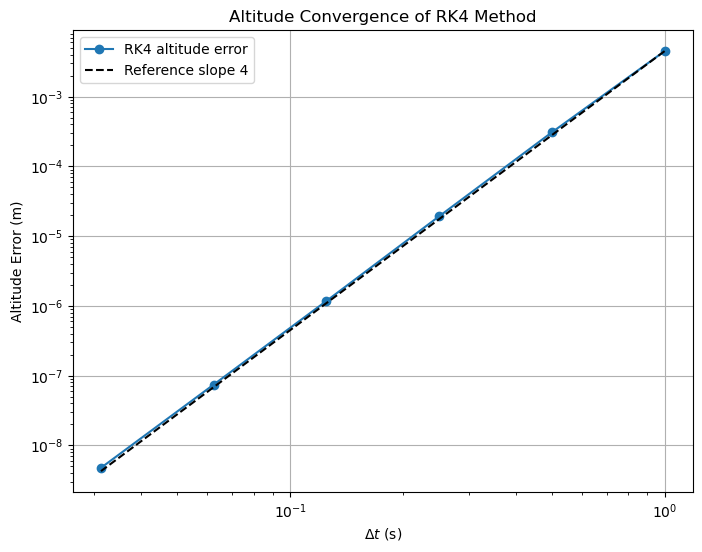

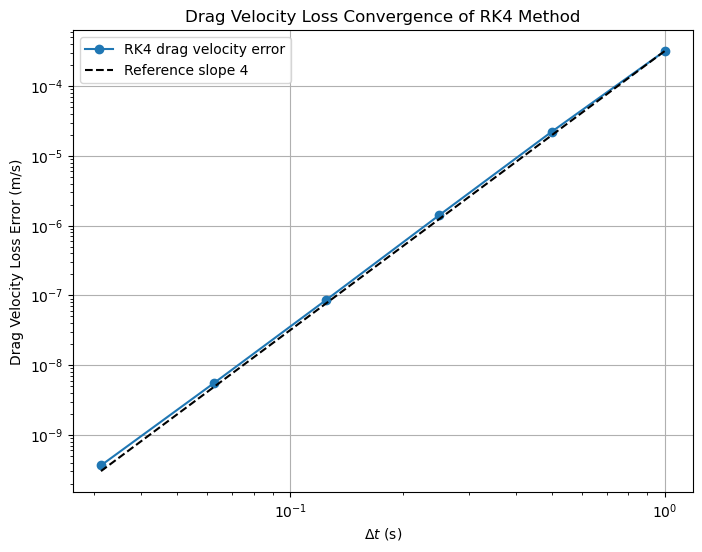

VELOCITY CONVERGENCE
------------------------
dt (s)       Error              Error ratio
1.0          4.00508251e-04   14.3237
0.5          2.79613166e-05   15.8447
0.25         1.76471053e-06   16.2879
0.125        1.08344693e-07   15.8076
0.0625       6.85395207e-09   16.3915
0.03125      4.18140189e-10   nan
ALTITUDE CONVERGENCE
------------------------
dt (s)       Error              Error ratio
1.0          4.49070346e-03   14.5865
0.5          3.07867012e-04   15.9818
0.25         1.92635434e-05   16.3531
0.125        1.17797390e-06   15.8001
0.0625       7.45549187e-08   15.6141
0.03125      4.77484718e-09   nan
DRAG VELOCITY LOSS CONVERGENCE
--------------------------------
dt (s)       Error              Error ratio
1.0          3.17861348e-04   14.2472
0.5          2.23104604e-05   15.8079
0.25         1.41134694e-06   16.2677
0.125        8.67574954e-08   15.7427
0.0625       5.51096946e-09   15.0637
0.03125      3.65844244e-10   nan
dt_ref: 0.0005508544921875


In [2]:
dts = np.array([1.0, 0.5, 0.25, 0.125, 0.0625, 0.03125])

N_ref = 40960
dt_ref = tb / N_ref

y_ref = np.array([0.0, 0.0, m0, 0.0])

for _ in range(N_ref):
    y_ref = rk4(y_ref, dt_ref)

errors_v = []
errors_h = []
errors_drag = []

for dt in dts:

    N = round(tb / dt)
    dt_actual = tb / N

    y = np.array([0.0, 0.0, m0, 0.0])

    for _ in range(N):
        y = rk4(y, dt_actual)

    errors_v.append(abs(y[1] - y_ref[1]))
    errors_h.append(abs(y[0] - y_ref[0]))
    errors_drag.append(abs(y[3] - y_ref[3]))

errors_v = np.array(errors_v)
errors_h = np.array(errors_h)
errors_drag = np.array(errors_drag)

ratios_v = errors_v[:-1] / errors_v[1:]
ratios_h = errors_h[:-1] / errors_h[1:]
ratios_drag = errors_drag[:-1] / errors_drag[1:]

v_ref_line = errors_v[0] * (dts / dts[0])**4
h_ref_line = errors_h[0] * (dts / dts[0])**4
drag_ref_line = errors_drag[0] * (dts / dts[0])**4


plt.figure(figsize=(8, 6))
plt.loglog(dts, errors_v, 'o-', label='RK4 velocity error')
plt.loglog(dts, v_ref_line, 'k--', label='Reference slope 4')
plt.xlabel(r'$\Delta t$ (s)')
plt.ylabel('Velocity Error (m/s)')
plt.title('Velocity Convergence of RK4 Method')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 6))
plt.loglog(dts, errors_h, 'o-', label='RK4 altitude error')
plt.loglog(dts, h_ref_line, 'k--', label='Reference slope 4')
plt.xlabel(r'$\Delta t$ (s)')
plt.ylabel('Altitude Error (m)')
plt.title('Altitude Convergence of RK4 Method')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 6))
plt.loglog(dts, errors_drag, 'o-', label='RK4 drag velocity error')
plt.loglog(dts, drag_ref_line, 'k--', label='Reference slope 4')
plt.xlabel(r'$\Delta t$ (s)')
plt.ylabel('Drag Velocity Loss Error (m/s)')
plt.title('Drag Velocity Loss Convergence of RK4 Method')
plt.legend()
plt.grid()
plt.show()


print('VELOCITY CONVERGENCE')
print('------------------------')
print("dt (s)       Error              Error ratio")

for i, dt in enumerate(dts):
    ratio = ratios_v[i] if i < len(ratios_v) else np.nan
    print(f"{dt:<12} {errors_v[i]:.8e}   {ratio:.4f}")

print('ALTITUDE CONVERGENCE')
print('------------------------')
print("dt (s)       Error              Error ratio")

for i, dt in enumerate(dts):
    ratio = ratios_h[i] if i < len(ratios_h) else np.nan
    print(f"{dt:<12} {errors_h[i]:.8e}   {ratio:.4f}")

print('DRAG VELOCITY LOSS CONVERGENCE')
print('--------------------------------')
print("dt (s)       Error              Error ratio")

for i, dt in enumerate(dts):
    ratio = ratios_drag[i] if i < len(ratios_drag) else np.nan
    print(f"{dt:<12} {errors_drag[i]:.8e}   {ratio:.4f}")

print('dt_ref:', dt_ref)

## Accuracy Analysis
This tested the accuracy of the RK4 applied to this problem with time steps of 1.0, 0.5, 0.25, 0.125, 0.0625, and 0.03125. The solutions of the RK4 using these time steps was compared against a much smaller time step of 0.0005508544921875. The error ratio as as the time steps are halved stay at around 16, which is consistant with that is expected of a fourth order method like the RK4, with the error decreasing proportionally to $\Delta t^4$. Plots show that although some error is accumulated over time, the RK4 method still approximates the solution well. This test shows that a time step of $\Delta t = 0.1s$ is sufficient for this IVP becauee of its low error. The RK4 is highly accurate for this IVP.

## Stability of the RK4 Method
The next thing to test is the stability of the RK4 method when applied to this problem. For the RK4, the stability function is  $$R(w)=1+w+\frac{w^2}{2}+\frac{w^3}{6}+\frac{w^4}{24}, \quad\quad\quad\quad\quad where\quad w = \lambda\Delta t$$
The RK4 is stable if $|R(w)| \leq 1$, which makes the stability boundary $w = -2.785$. This in turn sets $|\lambda|\Delta t \leq 2.785$. From this equation, the approximate stability limit is $\Delta t \approx 17.41$ at the largest magnitude eigenvalue $\lambda = 0.150805$. The time step we chose, $\Delta t = 0.1$, is much lower than the max time step, making the RK4 sufficiently stable for this problem

## Cost Considerations
The computational cost for utilizing the RK4 for this IVP is low. The RK4 method requires 4 evaluations per step, and since there are 226 steps in the interval of $\approx$ 22.6 seconds, the total number of evaluations on the interval is 904. This is a relatively small amount and coupled with the fact that the RK4 is an explicit method make the RK4 quite computationally efficient for this IVP.

## Mathematical Derivation of the RK4

If you have an arbitrary IVP of the form $y' = f(t,y)$, $y(t_n)=y_n$, starting from the Taylor expansion where $h = \Delta t$

$$
y(t_n+h)=y_n+hy_n'+\frac{h^2}{2!}y_n''+\frac{h^3}{3!}y_n'''+\cdots
$$

since $y' = f(t,y)$, the Taylor expansion can be rewritten as

$$
y_{n+1}=y_n+hf(t_n,y_n)+O(h^2).
$$

The RK4 splits a given interval into four stages, $k_1, k_2, k_3, k_4$.

The first slope is $k_1$, is $k_1=f(t_n,y_n)$, and the successive slopes use the previous ones, leading to:

- $t = t_n+c_2h$ and $y = y_n+ha_{21}k_1$, making $k_2=f\left(t_n+c_2h,\ y_n+ha_{21}k_1\right)$.
- For $k_3$, $t=t_n+c_3h$ and $y=y_n+h(a_{31}k_1+a_{32}k_2)$, making $k_3=f\left(t_n+c_3h,\ y_n+h(a_{31}k_1+a_{32}k_2)\right)$.
- Finally, $k_4$ also uses the previous slopes, leading to $t=t_n+c_4h$, $y=y_n+h(a_{41}k_1+a_{42}k_2+a_{43}k_3)$, and $k_4=f\left(t_n+c_4h,\ y_n+h(a_{41}k_1+a_{42}k_2+a_{43}k_3)\right)$.

Combining these 4 slopes gives an approximation

$$
y_{n+1}=y_n+h(b_1k_1+b_2k_2+b_3k_3+b_4k_4),
$$

where $b_1, b_2, b_3, b_4$ are the weights of the RK4.

$$
\begin{aligned}
k_1 = f(t_n, y_n),
k_2 = f\left(t_n+c_2h,\; y_n+h a_{21}k_1\right),
k_3 = f\left(t_n+c_3h,\; y_n+h(a_{31}k_1+a_{32}k_2)\right),
k_4 = f\left(t_n+c_4h,\; y_n+h(a_{41}k_1+a_{42}k_2+a_{43}k_3)\right),
y_{n+1} = y_n+h(b_1k_1+b_2k_2+b_3k_3+b_4k_4).
\end{aligned}
$$
The coefficients $a_{ij}$, $b_i$, $c_i$ are chosen so that $y_{n+1}$ agrees with the Taylor series of the exact solution through the $h^4$ term. $a_{ij}=0$ for $j\ge i$ and $c_1=0$. After this you get the complete RK4 method


$$\begin{aligned}
k_1 &= f(t_n,y_n),\\
k_2 &= f\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_1\right),\\
k_3 &= f\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_2\right),\\
k_4 &= f(t_n+h,y_n+hk_3),\\
y_{n+1} &= y_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4).
\end{aligned}$$



## Error Properties

Starting from the taylor expansion of an arbitrary IVP of the form $y' = f(t,y)$, $y(t_n)=y_n$, the exact solutions's taylor expansion is
$\begin{aligned}
y(t_n+h)={}&y_n+hf
+\frac{h^2}{2!}y_n''
+\frac{h^3}{3!}y_n''
&+\frac{h^4}{4!}y_n^{(4)}
+\frac{h^5}{5!}y_n^{(5)}
+O(h^6)
\end{aligned}$, and the RK4's expansion is $\\$ $\begin{aligned}
y_{n+1}={}&y_n+hy_n'
+\frac{h^2}{2!}y_n''
+\frac{h^3}{3!}y_n'''
&+\frac{h^4}{4!}y_n^{(4)}
+O(h^5).
\end{aligned}$ Comparing these two expansions show that the terms agree up until the $O(h^5)$ term, therefore the truncation error for a single step is $$\tau = O(h^5)$$. Over a the whole interval, the number of steps is for an arbitrary interval is $N = \frac{L}{h}$ where L is the interval length. Since the interval doesnt change, N is of order $O(h^{-1})$. The global truncation error is the truncation error accumulated over N steps, or $O(Nh^5) = O(h^4)$.

## Stability Property

### Stability Function
Let $w=\lambda h$. Applying RK4 to to this equation, you get

$$
k_1=\lambda y_n,\quad
k_2=\lambda y_n\left(1+\tfrac w2\right),\quad
k_3=\lambda y_n\left(1+\tfrac w2+\tfrac{w^2}{4}\right),\quad
k_4=\lambda y_n\left(1+w+\tfrac{w^2}{2}+\tfrac{w^3}{4}\right).
$$

Substituting into $y_{n+1}=y_n+\frac h6(k_1+2k_2+2k_3+k_4)$ gives

$$
y_{n+1}=R(w)\,y_n,\qquad R(w)=1+w+\frac{w^2}{2}+\frac{w^3}{6}+\frac{w^4}{24}.
$$

$R(w)$ is the Taylor series of $e^w$ truncated after the $w^4$ term. After N steps $y_n=R(w)^n y_0$, so the numerical solution decays only if $|R(w)|\le 1$.

## Algorithmic Summary of RK4 Method

RK4 advances the state from $t_k$ to $t_{k+1}=t_k+\Delta t$ using one fixed step. It evaluates the right-hand side four times inside the step, then combines the four slopes into a weighted average.

### One step, $t_k$ to $t_{k+1}$

Given $y_k \approx y(t_k)$ and the step size $\Delta t$:

1. Slope at the start of the step.
$$k_1 = f(y_k)$$

2. Slope at the midpoint, using $k_1$ to predict the state.
$$k_2 = f\!\left(y_k + \tfrac{\Delta t}{2}\,k_1\right)$$

3. Slope at the midpoint again, using $k_2$ to correct the predicted state.
$$k_3 = f\!\left(y_k + \tfrac{\Delta t}{2}\,k_2\right)$$

4. Slope at the end of the step, using $k_3$ to predict the end state.
$$k_4 = f\!\left(y_k + \Delta t\,k_3\right)$$

5. Weighted average of the four slopes, then repeat again.
$$y_{k+1} = y_k + \frac{\Delta t}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

The midpoint slopes carry weight $\tfrac{2}{6}$ each and the end slopes $\tfrac{1}{6}$ each. Each $k_i$ is a 4 component vector, so all four states $y= (h, v, m, \Delta v_{\text{drag}})^T$ are updated together.

### Full integration from start to finish

Inputs: $f$, $y_0=(0,\,0,\,m_0,\,0)^T$, burnout time $t_b$, number of steps $N$.

1. Set $\Delta t = t_b/N$, so the final step lands exactly on $t_b$.
2. For $k = 0, 1, \dots, N-1$:
   - compute $k_1,k_2,k_3,k_4$ from $y_k$,
   - compute $y_{k+1}$ from the update formula,
   - set $t_{k+1} = t_k + \Delta t$.
3. Return $y_N \approx y(t_b)$.

## Implementing RK4

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# parameters
g = 9.81
rho0 = 1.225
H = 8500

m0 = 50
m_dry = 20
T = 3000
Isp = 230
d = 0.15

# derived paramters
S = np.pi * d**2 / 4
mdot = T / (Isp * g)
t_b = (m0 - m_dry) / mdot


def rocket_burn_rhs(u, t, C_D):
    h, v, m, dv_drag = u

    rho_local = rho0 * np.exp(-h / H)
    drag_factor = (rho_local * C_D * S) / (2 * m)

    h_dot = v
    v_dot = (T / m) - g - drag_factor * v * abs(v)
    m_dot = -mdot
    dv_drag_dot = drag_factor * v**2

    return np.array([h_dot, v_dot, m_dot, dv_drag_dot], dtype=float)


def rk4_step(f, u_k, t_k, dt, C_D):
    y1 = f(u_k, t_k, C_D)
    y2 = f(u_k + 0.5 * dt * y1, t_k + 0.5 * dt, C_D)
    y3 = f(u_k + 0.5 * dt * y2, t_k + 0.5 * dt, C_D)
    y4 = f(u_k + dt * y3, t_k + dt, C_D)
    
    return u_k + (dt / 6) * (y1 + 2 * y2 + 2 * y3 + y4)


def solve_burn_ivp(n_steps, C_D):
    dt = t_b / n_steps
    t = np.linspace(0.0, t_b, n_steps + 1)
    u = np.zeros((n_steps + 1, 4), dtype=float)

    u[0] = np.array([0, 0, m0, 0])

    for k in range(n_steps):
        u[k + 1] = rk4_step(rocket_burn_rhs, u[k], t[k], dt, C_D)

    return t, u, dt

## Verifying the Convergence Rate and Accuracy

1. Analytical Special-Case Verification (C_D = 0)
Exact Burnout Altitude h(t_b) : 17313.581907 m
Exact Burnout Velocity v(t_b) : 1846.083748 m/s
Convergence Rate vs. Exact    : p = 3.9969

2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)
     N |    dt [s] |  Rel Err h(tb) |  Rel Err v(tb) | Rel Err dv_drag
--------------------------------------------------------------------
    10 |   2.25630 |     9.3646e-06 |     8.5937e-06 |      1.2165e-05
    20 |   1.12815 |     6.0091e-07 |     5.8288e-07 |      8.4156e-07
    40 |   0.56408 |     3.7793e-08 |     3.7470e-08 |      5.4470e-08
    80 |   0.28204 |     2.3675e-09 |     2.3656e-09 |      3.4602e-09
   160 |   0.14102 |     1.5000e-10 |     1.4573e-10 |      2.2561e-10
   320 |   0.07051 |     1.1362e-11 |     6.2792e-12 |      2.2157e-11
   640 |   0.03525 |     2.6965e-12 |     2.4569e-12 |      9.4025e-12
  1280 |   0.01763 |     2.1548e-12 |     3.0023e-12 |      8.6017e-12

Observed Full-Model Convergence Rate

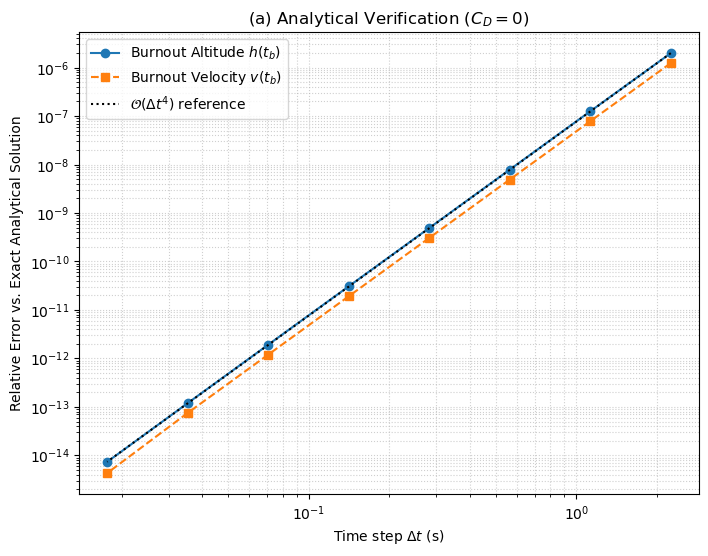

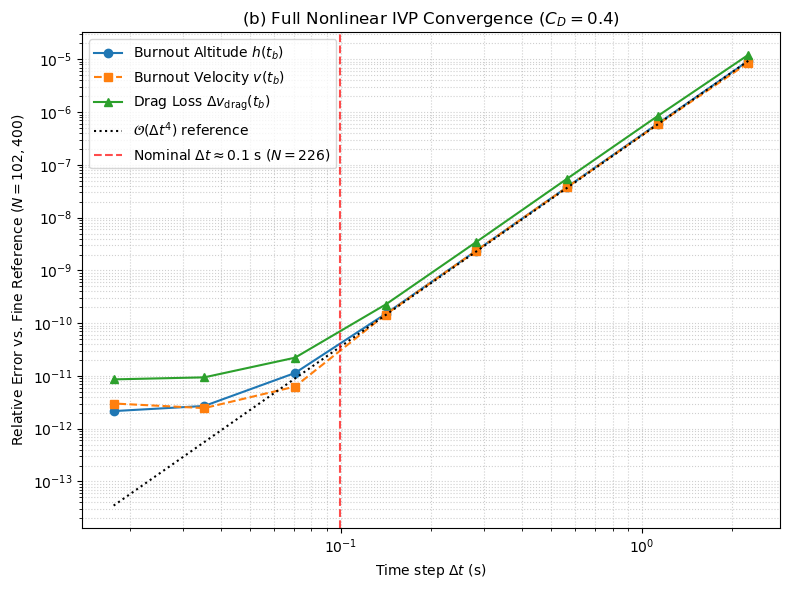

In [4]:
def exact_drag_free_solution(t):
    ve = Isp * g
    m_t = m0 - mdot * t

    v_exact = ve * np.log(m0 / m_t) - g * t
    h_exact = ve * (t + (m_t / mdot) * np.log(m_t / m0)) - 0.5 * g * (t ** 2)
    return h_exact, v_exact


ns = np.array([10, 20, 40, 80, 160, 320, 640, 1280])
dts = t_b / ns


# verify against exact solution (C_D = 0)
h_ex_tb, v_ex_tb = exact_drag_free_solution(t_b)
err_h_ideal = np.zeros(len(ns))
err_v_ideal = np.zeros(len(ns))

for i, n in enumerate(ns):
    t, u, dt = solve_burn_ivp(n, C_D=0.0)
    err_h_ideal[i] = abs(u[-1, 0] - h_ex_tb) / abs(h_ex_tb)
    err_v_ideal[i] = abs(u[-1, 1] - v_ex_tb) / abs(v_ex_tb)

rate_ideal = np.polyfit(np.log10(dts[:6]), np.log10(err_h_ideal[:6]), 1)[0]
print('1. Analytical Special-Case Verification (C_D = 0)')
print(f'Exact Burnout Altitude h(t_b) : {h_ex_tb:.6f} m')
print(f'Exact Burnout Velocity v(t_b) : {v_ex_tb:.6f} m/s')
print(f'Convergence Rate vs. Exact    : p = {rate_ideal:.4f}\n')


# show convergence and step size selection
t_ref, u_ref, dt_ref = solve_burn_ivp(n_steps=102400, C_D=0.4)
h_ref, v_ref, dv_ref = u_ref[-1, 0], u_ref[-1, 1], u_ref[-1, 3]

err_h_drag = np.zeros(len(ns))
err_v_drag = np.zeros(len(ns))
err_dv_drag = np.zeros(len(ns))

print('2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)')
print(f"{'N':>6} | {'dt [s]':>9} | {'Rel Err h(tb)':>14} | {'Rel Err v(tb)':>14} | {'Rel Err dv_drag':>15}")
print('-' * 68)

for i, n in enumerate(ns):
    t, u, dt = solve_burn_ivp(n, C_D=0.4)
    err_h_drag[i] = abs(u[-1, 0] - h_ref) / abs(h_ref)
    err_v_drag[i] = abs(u[-1, 1] - v_ref) / abs(v_ref)
    err_dv_drag[i] = abs(u[-1, 3] - dv_ref) / abs(dv_ref)

    print(f'{n:6d} | {dt:9.5f} | {err_h_drag[i]:14.4e} | {err_v_drag[i]:14.4e} | {err_dv_drag[i]:15.4e}')

rate_drag = np.polyfit(np.log10(dts[:6]), np.log10(err_h_drag[:6]), 1)[0]
print(f'\nObserved Full-Model Convergence Rate: p = {rate_drag:.4f}\n')


# momentum conservation identity check at dt = 0.1s
t_nom_0, u_nom_0, dt_nom_0 = solve_burn_ivp(n_steps=226, C_D=0.0)
t_nom_d, u_nom_d, dt_nom_d = solve_burn_ivp(n_steps=226, C_D=0.4)
dv_by_subtraction = u_nom_0[-1, 1] - u_nom_d[-1, 1]
dv_by_direct_state = u_nom_d[-1, 3]

print('3. Integral Momentum Conservation Check (at dt ~ 0.1 s)')
print(f'Drag loss via state subtraction (v_CD0 - v_CD0.4) : {dv_by_subtraction:.10f} m/s')
print(f'Drag loss via 4th state integral (dv_drag)        : {dv_by_direct_state:.10f} m/s')
print(f'Discrepancy between methods                       : {abs(dv_by_subtraction - dv_by_direct_state):.3e} m/s')


# plotting
fig, ax1 = plt.subplots(1, 1, figsize=(8,6))

# Left panel: Exact Analytical Verification (C_D = 0)
ax1.loglog(dts, err_h_ideal, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax1.loglog(dts, err_v_ideal, 's--', label=r'Burnout Velocity $v(t_b)$')
ax1.loglog(dts, err_h_ideal[0] * (dts / dts[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax1.set_xlabel(r'Time step $\Delta t$ (s)')
ax1.set_ylabel('Relative Error vs. Exact Analytical Solution')
ax1.set_title(r'(a) Analytical Verification ($C_D = 0$)')
ax1.grid(True, which='both', ls=':', alpha=0.6)
ax1.legend()

fig, ax2 = plt.subplots(1, 1, figsize=(8,6))

# Right panel: Full Nonlinear Drag Model Self-Convergence (C_D = 0.4)
ax2.loglog(dts, err_h_drag, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax2.loglog(dts, err_v_drag, 's--', label=r'Burnout Velocity $v(t_b)$')
ax2.loglog(dts, err_dv_drag, '^-', label=r'Drag Loss $\Delta v_{\mathrm{drag}}(t_b)$')
ax2.loglog(dts, err_h_drag[0] * (dts / dts[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax2.axvline(t_b / 226, color='r', ls='--', alpha=0.7, label=r'Nominal $\Delta t \approx 0.1$ s ($N=226$)')
ax2.set_xlabel(r'Time step $\Delta t$ (s)')
ax2.set_ylabel('Relative Error vs. Fine Reference ($N=102,400$)')
ax2.set_title(r'(b) Full Nonlinear IVP Convergence ($C_D = 0.4$)')
ax2.grid(True, which='both', ls=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

## Results: Aerodynamic Drag Effects

In [5]:
from pathlib import Path

fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)

N_RESULTS = 226
CD_BASELINE = 0.4
cd_values = [0.0,0.2,0.4,0.6]

results = {}

for cd in cd_values:
    t_run,u_run,dt_run = solve_burn_ivp(N_RESULTS, C_D=cd)
    results[cd] = {"t": t_run, "u": u_run}

#drag free and base solns
t_free = results[0.0]["t"]
u_free = results[0.0]["u"]

t_drag = results[CD_BASELINE]["t"]
u_drag = results[CD_BASELINE]["u"]

h_free, v_free = u_free[-1,0], u_free[-1,1]
h_drag, v_drag = u_drag[-1,0], u_drag[-1,1]

print("Burnout Results:")
print("CD    Altitude (m)    Velocity (m/s)    Alt. loss (%)    Vel. Loss (%)")

for cd in cd_values:
    u= results[cd]["u"]
    h_b, v_b = u[-1,0], u[-1,1]
    h_loss = 100*(h_free-h_b)/h_free
    v_loss = 100*(v_free-v_b)/v_free

    print(f"{cd:.1f}   {h_b:12.2f}   {v_b:14.2f}   {h_loss:12.2f}   {v_loss:12.2f}")

Burnout Results:
CD    Altitude (m)    Velocity (m/s)    Alt. loss (%)    Vel. Loss (%)
0.0       17313.58          1846.08           0.00           0.00
0.2       14807.02          1451.77          14.48          21.36
0.4       13043.78          1192.05          24.66          35.43
0.6       11740.04          1012.60          32.19          45.15


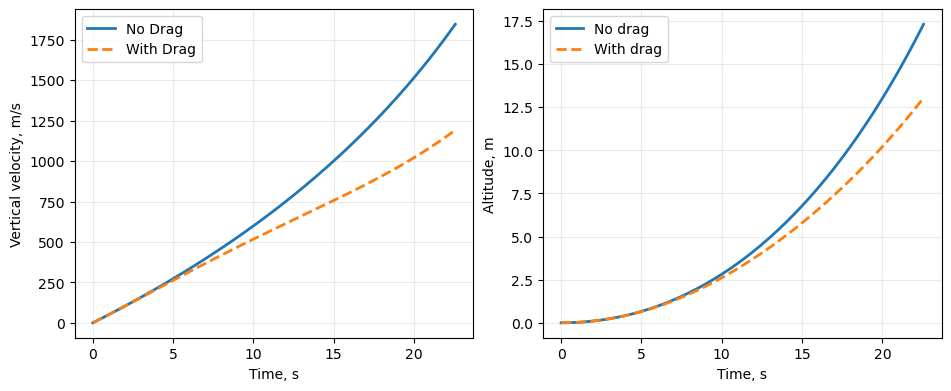

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8),
                         constrained_layout=True)

#Vel. comparison
axes[0].plot(t_free, u_free[:,1],
             label="No Drag", linewidth = 2)

axes[0].plot(t_drag, u_drag[:,1],
             "--", label="With Drag", linewidth=2)


axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Vertical velocity, m/s")
axes[0].legend()

#alt. comp.
axes[1].plot(t_free,u_free[:,0]/1000,label="No drag",linewidth=2)
axes[1].plot(t_drag, u_drag[:,0]/1000, "--", label="With drag", linewidth=2)

axes[1].set_xlabel("Time, s")
axes[1].set_ylabel("Altitude, m")
axes[1].legend()

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.savefig(fig_dir / "trajectory_comparison.pdf", bbox_inches="tight")

plt.show()

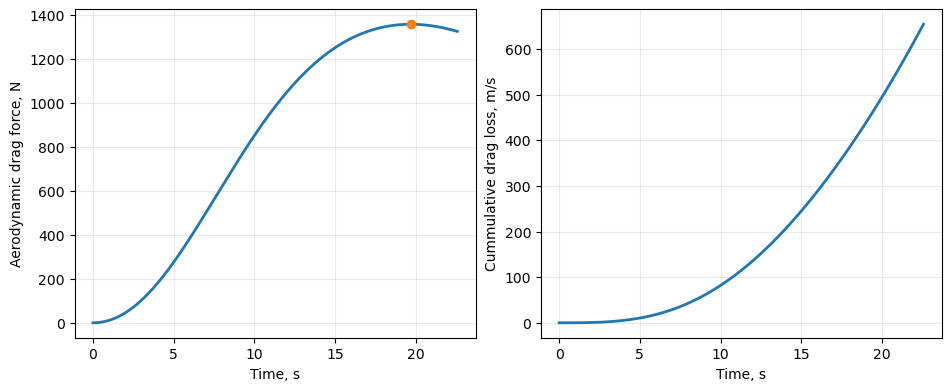

Maxmimum drag force: 1358.67 N
Time of maximum drag: 19.67 s
Altitude at maximum drag: 9878.52 m
Cumulative drag loss: 654.03 m/s


In [9]:
h = u_drag[:,0]
v = u_drag[:,1]
m = u_drag[:,2]
dv_drag = u_drag[:,3]

#atmos density and drag F
rho = rho0*np.exp(-h/H)
F_drag = 0.5*rho*CD_BASELINE*S*v**2
peak_idx = np.argmax(F_drag)

fig, axes = plt.subplots(1,2,figsize=(9.4,3.8),constrained_layout=True)

#drag forces over time
axes[0].plot(t_drag,F_drag,linewidth=2)
axes[0].plot(t_drag[peak_idx],F_drag[peak_idx],"o")
axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Aerodynamic drag force, N")

#int. drag induced v loss
axes[1].plot(t_drag,dv_drag,linewidth=2)

axes[1].set_xlabel("Time, s")
axes[1].set_ylabel("Cummulative drag loss, m/s")

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.savefig(fig_dir / "drag_force_and_loss.pdf", bbox_inches="tight")

plt.show()

print(f"Maxmimum drag force: {F_drag[peak_idx]:.2f} N")
print(f"Time of maximum drag: {t_drag[peak_idx]:.2f} s")
print(f"Altitude at maximum drag: {h[peak_idx]:.2f} m")
print(f"Cumulative drag loss: {dv_drag[-1]:.2f} m/s")

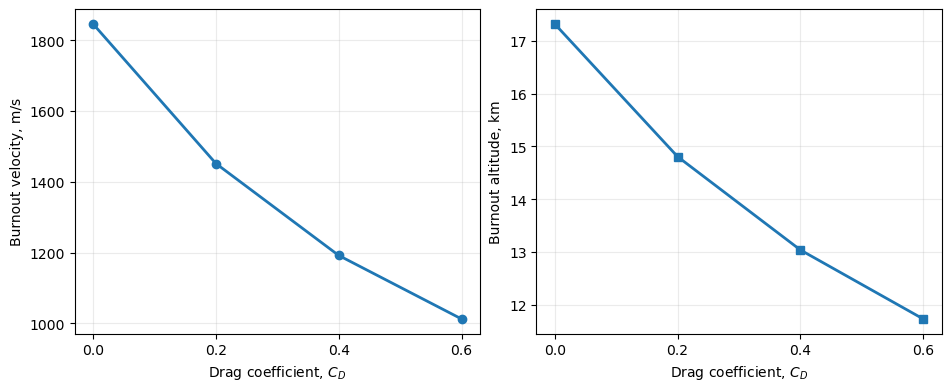

In [10]:
cd_array = np.array(cd_values)
burnout_v = np.array([
    results[cd]["u"][-1,1]
    for cd in cd_values
])

burnout_h = np.array([
    results[cd]["u"][-1,0]/1000
    for cd in cd_values
])

fig, axes = plt.subplots(1, 2, figsize=(9.4,3.8), constrained_layout=True)

axes[0].plot(cd_array, burnout_v, "o-", linewidth=2)
axes[0].set_xlabel(r"Drag coefficient, $C_D$")
axes[0].set_ylabel("Burnout velocity, m/s")

axes[1].plot(cd_array, burnout_h, "s-", linewidth=2)
axes[1].set_xlabel(r"Drag coefficient, $C_D$")
axes[1].set_ylabel("Burnout altitude, km")

for ax in axes:
    ax.set_xticks(cd_array)
    ax.grid(True, alpha=0.25)

fig.savefig(fig_dir / "drag_coefficient_sensitivity.pdf", bbox_inches="tight")

plt.show()